# Multi-fidelity scaling analysis

Analyze the scaling experiments stored in `mf_results/seed_*/fraction_*/run/report.json`. The notebook follows the cross-seed reporting pattern in `report_scaling_studies.py`: show each seed, the mean and sample-standard-deviation band for test RMSE, MAE, and NRMSE, plus summary and per-seed tables.

The selected trial is chosen using validation RMSE. The final test geometries (lhs-free-stream generalized geometries under `dataset/new_geom/lhs-free-stream`) are reported only after selection and are not used to select the model. The number of available seeds can vary by snapshot; the 100% snapshot may therefore have fewer observations than the others. The per-run reports are the source of truth rather than the aggregate CSV/JSON, which may contain results for runs no longer present in this folder.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 20
import numpy as np
import pandas as pd

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.alpha": 0.28,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 16,
        "figure.dpi": 120,
        "savefig.dpi": 160,
    }
)

candidates = (Path.cwd() / "train_mf_scaling_results", Path.cwd().parent / "train_mf_scaling_results", Path.cwd())
RESULTS_DIR = next(
    (path for path in candidates if any(path.glob("seed_*/fraction_*/run/report.json"))),
    None,
)
if RESULTS_DIR is None:
    raise FileNotFoundError(
        "Could not find mf_results/seed_*/fraction_*/run/report.json. "
        "Run this notebook from the repository root or the mf_results directory."
    )

print(f"Reading per-run reports from {RESULTS_DIR.resolve()}")

Reading per-run reports from /Users/yirenshen/Desktop/scitech27/train_mf_scaling_results


In [2]:
records = []
for report_path in sorted(RESULTS_DIR.glob("seed_*/fraction_*/run/report.json")):
    report = json.loads(report_path.read_text())
    test = report["final_test_geometry"]
    validation = report["validation_geometry"]
    if not np.isclose(float(report["test_rmse"]), float(test["rmse"])):
        raise ValueError(f"Inconsistent test RMSE in {report_path}")
    records.append(
        {
            "seed": int(report["seed"]),
            "fraction": float(report["fraction"]),
            "n_selected": int(report["n_selected"]),
            "n_training": int(report["n_training"]),
            "n_validation": int(report["n_validation"]),
            "n_test_cases": int(report["n_test_cases"]),
            "validation_rmse": float(validation["rmse"]),
            "test_rmse": float(test["rmse"]),
            "test_mae": float(test["mae"]),
            "test_nrmse_std": float(test["nrmse_std"]),
            "report_path": report_path,
        }
    )

runs = pd.DataFrame.from_records(records)
if runs.empty:
    raise FileNotFoundError(f"No per-run reports found under {RESULTS_DIR}")
if runs.duplicated(["seed", "fraction"]).any():
    duplicates = runs.loc[runs.duplicated(["seed", "fraction"], keep=False), ["seed", "fraction"]]
    raise ValueError(f"Duplicate seed/fraction reports found:\n{duplicates}")

runs = runs.sort_values(["fraction", "seed"]).reset_index(drop=True)
print(f"Loaded {len(runs)} reports from seeds {sorted(runs['seed'].unique())}.")
display(runs.drop(columns="report_path"))

Loaded 40 reports from seeds [7, 27, 207, 353, 3407].


,seed,fraction,n_selected,n_training,n_validation,n_test_cases,validation_rmse,test_rmse,test_mae,test_nrmse_std
0,7,0.06,36,25,11,44,0.302170,0.352232,0.231543,0.697889
1,27,0.06,36,25,11,44,0.369162,0.329953,0.211085,0.653747
2,207,0.06,36,25,11,44,0.290840,0.363678,0.238465,0.720568
3,353,0.06,36,25,11,44,0.388731,0.497686,0.391415,0.986082
4,3407,0.06,36,25,11,44,0.458540,0.443147,0.315595,0.878022
5,7,0.10,60,42,18,44,0.278403,0.328954,0.198517,0.651768
6,27,0.10,60,42,18,44,0.282255,0.327599,0.207339,0.649084
7,207,0.10,60,42,18,44,0.266711,0.409983,0.283938,0.812314
8,353,0.10,60,42,18,44,0.269209,0.309316,0.203855,0.612858
9,3407,0.10,60,42,18,44,0.324240,0.316202,0.207009,0.626502


## Test error versus training snapshot

Each seed line is the selected model's score on unseen test geometries. The red curve is the mean across the available seeds at that snapshot, and the shaded region is ±1 sample standard deviation (`ddof=1`). Snapshots with one run have no estimable standard deviation; snapshots with fewer seeds are labeled in the summary table below.

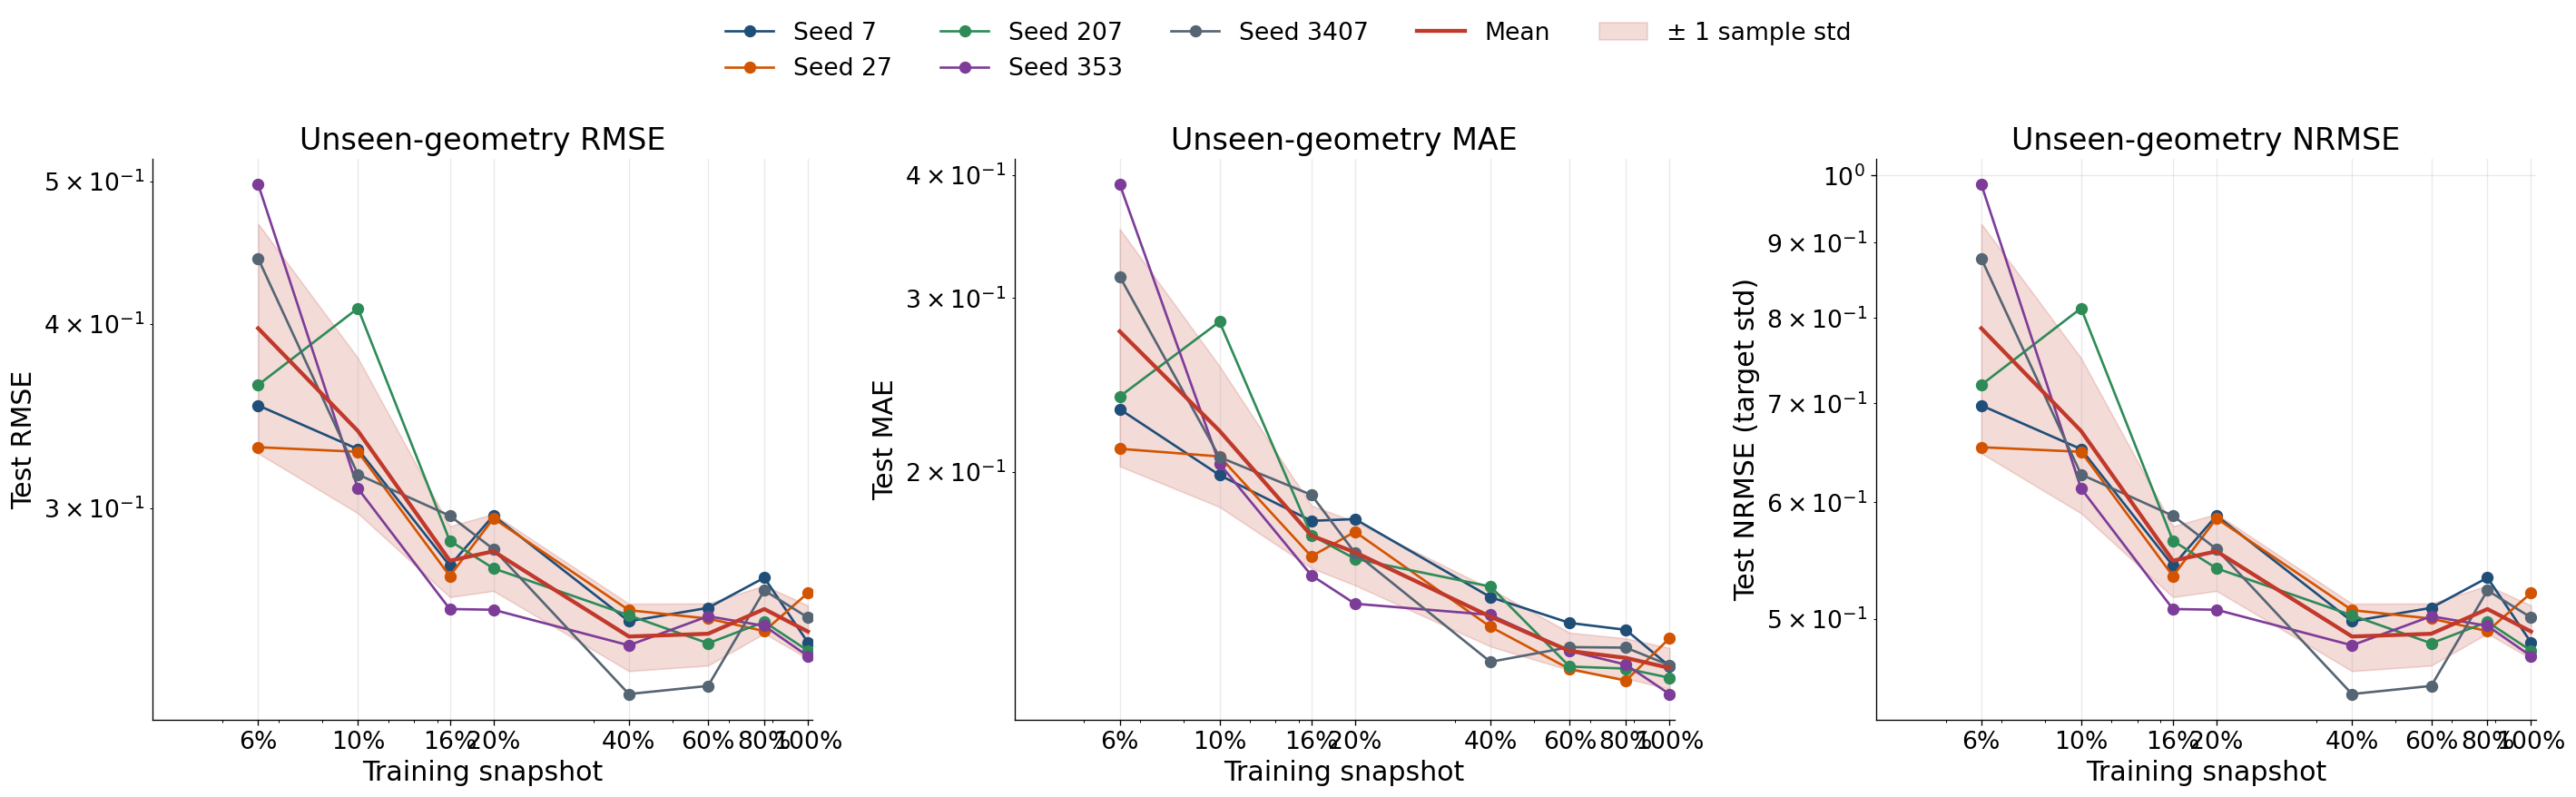

In [3]:
metric_specs = (
    ("test_rmse", "Test RMSE", "Unseen-geometry RMSE"),
    ("test_mae", "Test MAE", "Unseen-geometry MAE"),
    ("test_nrmse_std", "Test NRMSE (target std)", "Unseen-geometry NRMSE"),
)
summary = (
    runs.groupby("fraction", as_index=False)
    .agg(
        n_selected=("n_selected", "first"),
        n_training=("n_training", "first"),
        n_validation=("n_validation", "first"),
        n_seeds=("seed", "nunique"),
        **{
            f"{metric}_{stat}": (metric, stat)
            for metric, _, _ in metric_specs
            for stat in ("mean", "std")
        },
    )
    .sort_values("fraction")
    .reset_index(drop=True)
)

seed_colors = ["#1f4e79", "#d35400", "#2e8b57", "#7d3c98", "#566573"]
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
x = summary["n_selected"].to_numpy(dtype=float)
tick_labels = [
    f"{fraction:.0%}"
    for fraction, count in zip(summary["fraction"], summary["n_selected"])
]

for ax, (metric, ylabel, title) in zip(axes, metric_specs):
    for color, seed in zip(seed_colors, sorted(runs["seed"].unique())):
        seed_runs = runs[runs["seed"] == seed].sort_values("fraction")
        ax.plot(
            seed_runs["n_selected"],
            seed_runs[metric],
            color=color,
            marker="o",
            markersize=7,
            linewidth=1.6,
            label=f"Seed {seed}",
        )

    mean = summary[f"{metric}_mean"].to_numpy(dtype=float)
    std = summary[f"{metric}_std"].to_numpy(dtype=float)
    ax.plot(x, mean, color="#c0392b", linewidth=2.6, label="Mean", zorder=4)
    has_sample_std = summary["n_seeds"].to_numpy() > 1
    ax.fill_between(
        x,
        mean - std,
        mean + std,
        where=has_sample_std & np.isfinite(std),
        color="#c0392b",
        alpha=0.18,
        label="± 1 sample std",
        zorder=1,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel("Training snapshot")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xlim(x[0] - 15, x[-1] + 15)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=min(5, len(labels)), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

## Cross-seed summary

RMSE, MAE, and NRMSE are computed over test panels, as recorded in each run report. NRMSE here is RMSE divided by the standard deviation of the test target. Summary standard deviations are sample standard deviations across runs, not confidence intervals. The fit/validation case counts describe the selected subset and its 70/30 split.

In [4]:
summary_display = summary.copy()
summary_display["snapshot"] = summary_display["fraction"].map(lambda value: f"{value:.0%}")
for metric, _, _ in metric_specs:
    summary_display[f"{metric} (mean ± std)"] = summary_display.apply(
        lambda row: (
            f"{row[f'{metric}_mean']:.4f} ± {row[f'{metric}_std']:.4f}"
            if row["n_seeds"] > 1
            else f"{row[f'{metric}_mean']:.4f} ± N/A"
        ),
        axis=1,
    )

display(
    summary_display[
        [
            "snapshot",
            "n_selected",
            "n_training",
            "n_validation",
            "n_seeds",
            *[f"{metric} (mean ± std)" for metric, _, _ in metric_specs],
        ]
    ].rename(
        columns={
            "snapshot": "Snapshot",
            "n_selected": "Selected cases",
            "n_training": "Fit cases",
            "n_validation": "Validation cases",
            "n_seeds": "Available seeds",
        }
    )
)

,Snapshot,Selected cases,Fit cases,Validation cases,Available seeds,test_rmse (mean ± std),test_mae (mean ± std),test_nrmse_std (mean ± std)
0,6%,36,25,11,5,0.3973 ± 0.0705,0.2776 ± 0.0750,0.7873 ± 0.1397
1,10%,60,42,18,5,0.3384 ± 0.0408,0.2201 ± 0.0358,0.6705 ± 0.0809
2,16%,96,67,29,5,0.2763 ± 0.0153,0.1724 ± 0.0126,0.5475 ± 0.0303
3,20%,120,84,36,5,0.2804 ± 0.0168,0.1658 ± 0.0123,0.5556 ± 0.0333
4,40%,240,168,72,5,0.2455 ± 0.0129,0.1427 ± 0.0096,0.4863 ± 0.0256
5,60%,360,252,108,5,0.2465 ± 0.0119,0.1317 ± 0.0058,0.4884 ± 0.0237
6,80%,480,336,144,5,0.2562 ± 0.0096,0.1296 ± 0.0060,0.5077 ± 0.0190
7,100%,600,420,180,5,0.2474 ± 0.0103,0.1266 ± 0.0061,0.4901 ± 0.0204


## Test RMSE by seed

This makes missing seed/fraction runs explicit instead of silently treating them as zero or filling them from the aggregate CSV.

In [5]:
rmse_by_seed = runs.pivot(index="fraction", columns="seed", values="test_rmse")
rmse_by_seed.index = [f"{fraction:.0%}" for fraction in rmse_by_seed.index]
rmse_by_seed.columns = [f"Seed {seed}" for seed in rmse_by_seed.columns]
display(rmse_by_seed.style.format("{:.4f}").set_caption("Unseen-geometry test RMSE (ΔCp)"))

,Seed 7,Seed 27,Seed 207,Seed 353,Seed 3407
6%,0.3522,0.3300,0.3637,0.4977,0.4431
10%,0.3290,0.3276,0.4100,0.3093,0.3162
16%,0.2742,0.2698,0.2851,0.2562,0.2964
20%,0.2965,0.2952,0.2731,0.2559,0.2814
40%,0.2514,0.2558,0.2537,0.2421,0.2244
60%,0.2567,0.2524,0.2429,0.2534,0.2272
80%,0.2691,0.2475,0.2511,0.2496,0.2638
100%,0.2432,0.2627,0.2401,0.2380,0.2528
